In [290]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder , MinMaxScaler 
from sklearn.preprocessing import RobustScaler
from category_encoders import TargetEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
import seaborn as sns
from sklearn.preprocessing import MinMaxScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import accuracy_score
from sklearn.metrics import f1_score
import numpy as np
from sklearn.metrics import classification_report

In [291]:
df = pd.read_csv("loan_data.csv")
df.info

<bound method DataFrame.info of        person_age person_gender person_education  person_income  \
0            22.0        female           Master        71948.0   
1            21.0        female      High School        12282.0   
2            25.0        female      High School        12438.0   
3            23.0        female         Bachelor        79753.0   
4            24.0          male           Master        66135.0   
...           ...           ...              ...            ...   
44995        27.0          male        Associate        47971.0   
44996        37.0        female        Associate        65800.0   
44997        33.0          male        Associate        56942.0   
44998        29.0          male         Bachelor        33164.0   
44999        24.0          male      High School        51609.0   

       person_emp_exp person_home_ownership  loan_amnt        loan_intent  \
0                   0                  RENT    35000.0           PERSONAL   
1        

In [292]:
x = df.drop(columns='loan_status')
y = df['loan_status']

In [293]:
xtrain,xtest,ytrain,ytest = train_test_split(x,y,train_size=0.8,random_state=42)

In [294]:
df.head()

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22.0,female,Master,71948.0,0,RENT,35000.0,PERSONAL,16.02,0.49,3.0,561,No,1
1,21.0,female,High School,12282.0,0,OWN,1000.0,EDUCATION,11.14,0.08,2.0,504,Yes,0
2,25.0,female,High School,12438.0,3,MORTGAGE,5500.0,MEDICAL,12.87,0.44,3.0,635,No,1
3,23.0,female,Bachelor,79753.0,0,RENT,35000.0,MEDICAL,15.23,0.44,2.0,675,No,1
4,24.0,male,Master,66135.0,1,RENT,35000.0,MEDICAL,14.27,0.53,4.0,586,No,1


In [295]:
cat_cols = x.select_dtypes(include='object').columns
df[cat_cols].nunique() # OneHotEncoder

person_gender                     2
person_education                  5
person_home_ownership             4
loan_intent                       6
previous_loan_defaults_on_file    2
dtype: int64

In [296]:
num_cols = x.select_dtypes(include='number').columns

<Axes: >

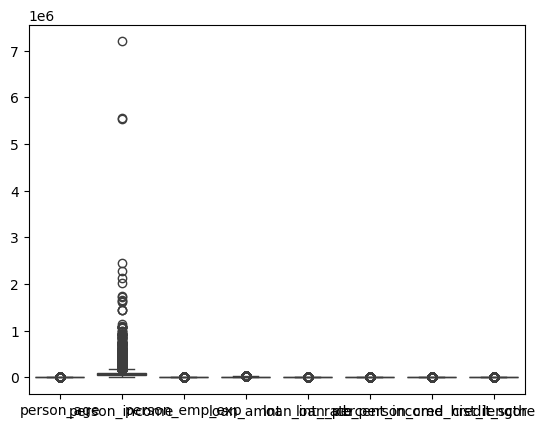

In [297]:
sns.boxplot(df[num_cols])

In [298]:
preprocessing = ColumnTransformer(
    transformers= [
        ('scaling',RobustScaler(),num_cols),
        ('encoder',OneHotEncoder(handle_unknown='ignore'),cat_cols)
    ]
)
preprocessing

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scaling', ...), ('encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``featur

In [299]:
main_pipeline = Pipeline(
    steps= [ 
        ('pre',preprocessing),
        ('model',LogisticRegression(penalty = 'l1',solver = 'saga'))
    ]
)
main_pipeline.fit(xtrain,ytrain)

c:\anacondadistribution\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
c:\anacondadistribution\Lib\site-packages\sklearn\linear_model\_logistic.py:1429: UserWarning: Inconsistent values: penalty=l1 with l1_ratio=0.0. penalty is deprecated. Please use l1_ratio only.
  warnings.warn(
c:\anacondadistribution\Lib\site-packages\sklearn\linear_model\_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](13,)","['person_age','person_gender','person_education',..., 'cb_person_cred_hist_length','credit_score', 'previous_loan_defaults_on_file']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,13
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('scaling', ...), ('encoder', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of

## CLASSIFICATION METRICS

## Confusion Metrix

## Train Data

In [300]:
ytrain.value_counts()

loan_status
0    28010
1     7990
Name: count, dtype: int64

In [301]:
ytrain_pred = main_pipeline.predict(xtrain)
print(classification_report(ytrain,ytrain_pred))

              precision    recall  f1-score   support

           0       0.93      0.94      0.93     28010
           1       0.78      0.74      0.76      7990

    accuracy                           0.90     36000
   macro avg       0.85      0.84      0.85     36000
weighted avg       0.90      0.90      0.90     36000



In [302]:
ytrain_pred = main_pipeline.predict(xtrain)
cm_train = confusion_matrix(ytrain,ytrain_pred)

In [303]:
cm_train

array([[26338,  1672],
       [ 2048,  5942]], dtype=int64)

In [304]:
cm_train[:,1].sum()

7614

## Test Data

In [305]:
ytest.value_counts()

loan_status
0    6990
1    2010
Name: count, dtype: int64

In [ ]:
ytest_pred = main_pipeline.predict(xtest)
print(classification_report(ytest,ytest_pred))

              precision    recall  f1-score   support

           0       0.93      0.94      0.93      6990
           1       0.78      0.74      0.76      2010

    accuracy                           0.89      9000
   macro avg       0.85      0.84      0.84      9000
weighted avg       0.89      0.89      0.89      9000



In [307]:
ytest_pred = main_pipeline.predict(xtest)
cm_test = confusion_matrix(ytest,ytest_pred)

In [308]:
cm_test

array([[6562,  428],
       [ 525, 1485]], dtype=int64)

## Precision Score for Yes/True

In [309]:
cm_train[:,1].sum()

7614

In [310]:
precision_score(ytrain,ytrain_pred,pos_label=True)

0.7804045179931705

## Conclusion -

out of all predicted (686 True labels) 77% labels are correctly predicted as True

out of all predicted (686 True labels) 23% labels are wrongly predicted as True

## Precision Score for No/False

In [311]:
cm_train[:].sum()

36000

In [312]:
precision_score(ytrain,ytrain_pred,pos_label=False)

0.9278517579088283

## Conclusion -

out of (36000 false labels) 92% labels are correctly predicted as false

out of (36000 false labels) 08% labels are wrongly predicted as false


## Precision score for Yes/true

In [313]:
cm_test[1:,].sum()

2010

In [314]:
precision_score(ytest,ytest_pred,pos_label=True)

0.7762676424464192

## Conclusion

out of (2010 true labels) 77 % labels are correctly predicted as true

out of (2010 true labels) 23 % labels are wrongly predicted as true

## precision score for No/false

In [315]:
cm_test[:,0].sum()

7087

In [316]:
precision_score(ytest,ytest_pred,pos_label=False)

0.925920699873007

## Conclusion

out of (7064 false labels) 92 % labels are truely predicted as false

out of (7064 false labels) 08 % labels are falsely predicted as false

## recall score for yes/true

In [317]:
cm_train[:,1].sum()

7614

In [318]:
recall_score(ytrain,ytrain_pred,pos_label=True)

0.7436795994993742

## Conclusion

out of all predicted (7691 true labels) 74 % labels are correctly predicted as true

out of all predicted (7691 true labels) 26 % labels are wrongly predicted as true



## recall score for no/false

In [319]:
cm_train[:].sum()

36000

In [320]:
recall_score(ytrain,ytrain_pred,pos_label=False)

0.9403070332024277

## Conclusion

out of all predicted (36000 false labels) 93 % labels are correctly predicted as false

out of all predicted (36000 false labels) 07 % labels are wrongly predicted as false

## recall score for yes/true

In [321]:
cm_test[1:,].sum()

2010

In [322]:
recall_score(ytest,ytest_pred,pos_label=True)

0.7388059701492538

## Conclusion

out of all predicted (2010 true labels) 74 % labels are correctly predicted as true

out of all predicted (2010 true labels) 26 % labels are wrongly predicted as true

## recall score for no/false

In [323]:
cm_test[:,0].sum()

7087

In [324]:
recall_score(ytest,ytest_pred,pos_label=False)

0.9387696709585122

## Conclusion

out of all predicted (7074 true labels) 93 % labels are correctly predicted as false

out of all predicted (7074 true labels) 07 % labels are wrongly predicted as false

## accuracy score for yes

In [325]:
cm_train[:,1].sum()

7614

In [326]:
accuracy_score(ytrain,ytrain_pred)

0.8966666666666666

## Conclusion

out of all predicted (7687 true labels) 89 % labels are correctly predicted as true

out of all predicted (7687 true labels) 11 % labels are wrongly predicted as true

## accuracy score for no

In [327]:
cm_train[:].sum()

36000

In [328]:
accuracy_score(ytrain,ytrain_pred)

0.8966666666666666

## Conclusion

out of all predicted (36000 false labels) 89 % labels are correctly predicted as false

out of all predicted (36000 false labels) 11 % labels are wrongly predicted as false

## accuracy score for yes

In [329]:
cm_test[1:,].sum()

2010

In [330]:
accuracy_score(ytest,ytest_pred)

0.8941111111111111

## Conclusion

out of all predicted (2010 true labels) 89 % labels are correctly predicted as true

out of all predicted (2010 true labels) 11 % labels are wrongly predicted as true

## accuracy score for no

In [331]:
cm_test[:,0].sum()

7087

In [332]:
accuracy_score(ytest,ytest_pred)

0.8941111111111111

## Conclusion

out of all predicted (7074 true labels) 89 % labels are correctly predicted as false

out of all predicted (7074 true labels) 11 % labels are wrongly predicted as false

## f1 score for yes/true

In [333]:
cm_train[:,1].sum()

7614

In [334]:
f1_score(ytrain,ytrain_pred,pos_label=True)

0.7615995898487568

## Conclusion

out of all predicted (7687 true labels) 76 % labels are correctly predicted as true

out of all predicted (7687 true labels) 24 % labels are wrongly predicted as true

## f1 score for no/false

In [335]:
cm_train[:].sum()

36000

In [336]:
f1_score(ytrain,ytrain_pred,pos_label=False)

0.9340378750265976

## Conclusion

out of all predicted (36000 true labels) 93 % labels are correctly predicted as false

out of all predicted (36000 true labels) 07 % labels are wrongly predicted as false

## f1 score for yes/true


In [337]:
cm_test[1:,].sum()

2010

In [338]:
f1_score(ytest,ytest_pred,pos_label=True)

0.7570736681111394

## Conclusion

out of all predicted (2010 true labels) 75 % labels are correctly predicted as true

out of all predicted (2010 true labels) 25 % labels are wrongly predicted as true

## f1 score for no/false

In [339]:
cm_test[:,0].sum()

7087

In [340]:
f1_score(ytest,ytest_pred,pos_label=False)

0.932300916388435

## Conclusion

out of all predicted (7074 true labels) 93 % labels are correctly predicted as false

out of all predicted (7074 true labels) 07 % labels are wrongly predicted as false